# 💧 WaterWallet — ML Module
**Physics-Informed Machine Learning for Rainwater Harvesting Decision Support**

VESIT · Capstone 2025-26 · Guide: Dr. Mrs. Gresha Bhatia

---

## What this notebook does

| # | Problem | Type | Data |
|---|---|---|---|
| 1 | Predict monthly rainwater yield for a rooftop | Regression | Real — Open-Meteo API (Thane, 2010–2025) |
| 2 | Recommend RWH system type for a site | Classification | Realistic synthetic from engineering rules |

**Data transparency**
- Problem 1: Real rainfall data from Open-Meteo Archive API (Thane, 2010–2025)
- Problem 2: Synthetic site data from BMC / CPHEEO engineering rules. One real
  Thane society used for final validation.

> **Production parity and output freshness:** The classifier and yield training cells below now mirror `backend/ml_models/train_models.py`. The rainfall forecast evaluation remains a separate 2022-2025 experiment; the deployed yield model trains through 2024. Saved outputs from the old classifier/yield experiment have been cleared. Rerun the notebook cells from the synthetic classifier dataset onward before citing their metrics.


In [ ]:
# ============================================================
# CELL 1 — Install and import libraries
# ============================================================
# Install everything once. Wait for this to finish before running any other cell.

!pip install -q requests pandas numpy matplotlib seaborn scikit-learn shap
!pip install -q statsmodels pmdarima tensorflow

import requests
import warnings
import time
import math

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.ensemble        import (RandomForestRegressor,
                                     RandomForestClassifier,
                                     GradientBoostingRegressor)
from sklearn.tree            import DecisionTreeClassifier, export_text
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing   import LabelEncoder, StandardScaler
from sklearn.metrics         import (mean_absolute_error, mean_squared_error,
                                     r2_score, accuracy_score,
                                     classification_report, confusion_matrix)

from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima import auto_arima

import tensorflow as tf
from tensorflow.keras.models   import Sequential
from tensorflow.keras.layers   import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings('ignore')
np.random.seed(42)
tf.random.set_seed(42)

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 11
})

CONFIG_COLORS = {
    'Storage-Only':      '#378ADD',
    'Borewell-Recharge': '#1D9E75',
    'Hybrid':            '#7F77DD'
}

print('All libraries ready.')

All libraries ready.


In [ ]:
# ============================================================
# CELL 2 — Fetch real rainfall data (Open-Meteo, 2010–2025)
# ============================================================
"""
We call the Open-Meteo Archive API — free, no key needed — for 15 years
of daily precipitation for Thane (lat 19.22, lon 72.97). Daily records
are aggregated to monthly totals. This extended dataset (2010–2025)
provides 180 monthly observations for more robust model evaluation.
"""

THANE_LAT = 19.22
THANE_LON = 72.97

print('Fetching rainfall data 2010–2025 from Open-Meteo ...')
resp = requests.get(
    'https://archive-api.open-meteo.com/v1/archive',
    params={
        'latitude':   THANE_LAT,
        'longitude':  THANE_LON,
        'start_date': '2010-01-01',
        'end_date':   '2025-12-31',
        'daily':      'precipitation_sum',
        'timezone':   'Asia/Kolkata'
    },
    timeout=30
)
resp.raise_for_status()
raw = resp.json()

daily = pd.DataFrame({
    'date':    raw['daily']['time'],
    'rain_mm': raw['daily']['precipitation_sum']
})
daily['date']    = pd.to_datetime(daily['date'])
daily['rain_mm'] = daily['rain_mm'].fillna(0)
daily['year']    = daily['date'].dt.year
daily['month']   = daily['date'].dt.month

# Aggregate daily → monthly
monthly = daily.groupby(['year', 'month']).agg(
    rain_mm    = ('rain_mm', 'sum'),
    peak_day   = ('rain_mm', 'max'),
    rainy_days = ('rain_mm', lambda x: (x > 1).sum())
).reset_index()

print(f'Daily records : {len(daily):,}')
print(f'Monthly rows  : {len(monthly)}')
print(f'Years covered : {monthly.year.min()} – {monthly.year.max()}')
print(f'Annual avg    : {monthly.groupby("year")["rain_mm"].sum().mean():.0f} mm/yr')
display(monthly.tail(14))

Fetching rainfall data 2010–2025 from Open-Meteo ...
Daily records : 5,844
Monthly rows  : 192
Years covered : 2010 – 2025
Annual avg    : 1823 mm/yr


,year,month,rain_mm,peak_day,rainy_days
178,2024,11,0.5,0.5,0
179,2024,12,1.6,0.5,0
180,2025,1,0.1,0.1,0
181,2025,2,0.0,0.0,0
182,2025,3,0.0,0.0,0
183,2025,4,3.7,3.4,1
184,2025,5,155.0,59.6,22
185,2025,6,631.7,83.5,27
186,2025,7,467.0,41.1,31
187,2025,8,493.3,107.1,30


In [ ]:
# ============================================================
# CELL 3 — Prepare rainfall series and train/test split
# ============================================================
"""
Temporal split: train on 2010–2021 (144 months), test on 2022–2025
(48 months). A temporal split is mandatory for time-series — a random
split would leak future months into training (data leakage).
"""

TRAIN_END_YEAR  = 2021
TEST_START_YEAR = 2022

rainfall = monthly[['year', 'month', 'rain_mm']].copy()
rainfall['rain_mm'] = pd.to_numeric(rainfall['rain_mm'], errors='coerce').clip(lower=0)
rainfall = rainfall.dropna().sort_values(['year', 'month']).reset_index(drop=True)
rainfall['date'] = pd.to_datetime(
    rainfall['year'].astype(str) + '-' + rainfall['month'].astype(str) + '-01'
)

train_data = rainfall[rainfall['year'] <= TRAIN_END_YEAR].copy()
test_data  = rainfall[rainfall['year'] >= TEST_START_YEAR].copy()

print(f'Training set : {len(train_data)} months ({train_data.year.min()}–{train_data.year.max()})')
print(f'Test set     : {len(test_data)} months  ({test_data.year.min()}–{test_data.year.max()})')

Training set : 144 months (2010–2021)
Test set     : 48 months  (2022–2025)


In [ ]:
# ============================================================
# CELL 4 — Model 1: Same-Month-Last-Year Baseline
# ============================================================
"""
The dumbest possible forecast: predict this month's rainfall as
whatever it was exactly one year ago. Every ML model must beat this
to demonstrate it adds value.
"""

rainfall_lookup      = dict(zip(rainfall['date'], rainfall['rain_mm']))
baseline_predictions = []

for _, row in test_data.iterrows():
    prev_year_date = row['date'] - pd.DateOffset(years=1)
    pred = rainfall_lookup.get(prev_year_date, train_data['rain_mm'].mean())
    baseline_predictions.append(max(0, pred))

print(f'Baseline predictions generated: {len(baseline_predictions)}')

Baseline predictions generated: 48


In [ ]:
# ============================================================
# CELL 5 — Model 2: Auto-SARIMA
# ============================================================
"""
auto_arima searches over seasonal ARIMA parameter combinations and
selects the best order by minimising AIC. This is more rigorous than
manually choosing (1,0,1)(1,1,1,12) — the selected order is data-driven.
"""

train_series = train_data.set_index('date')['rain_mm'].asfreq('MS')

print('Running auto_arima to find optimal SARIMA parameters ...')
auto_model = auto_arima(
    train_series,
    seasonal=True,
    m=12,
    suppress_warnings=True,
    stepwise=True,
    error_action='ignore'
)

best_sarima_order = f'SARIMA{auto_model.order}x{auto_model.seasonal_order}'
print(f'Best order selected : {best_sarima_order}')

sarima_fit         = auto_model.fit(train_series)
sarima_predictions = np.maximum(np.asarray(
    sarima_fit.predict(n_periods=len(test_data))
), 0)

print(f'SARIMA predictions generated: {len(sarima_predictions)}')

Running auto_arima to find optimal SARIMA parameters ...
Best order selected : SARIMA(0, 0, 2)x(2, 0, 1, 12)
SARIMA predictions generated: 48


In [ ]:
# ============================================================
# CELL 6 — Model 3: Random Forest Rainfall Predictor (recursive)
# ============================================================
"""
Random Forest with lag features. Predictions are generated recursively:
each forecast is appended to the history before computing the next step's
lag features — mirroring real deployment conditions.

Note: RF underperforms Auto-SARIMA on this task. This is an expected and
honest result — autoregressive ML on small, zero-inflated monsoon series
tends to collapse toward the mean. The result is reported transparently
as evidence that SARIMA is the correct model choice here.
"""

rf_data = rainfall.copy()
rf_data['rain_lag1']  = rf_data['rain_mm'].shift(1)
rf_data['rain_lag12'] = rf_data['rain_mm'].shift(12)
rf_data['rain_roll3'] = rf_data['rain_mm'].shift(1).rolling(3).mean()
rf_data['month_sin']  = np.sin(2 * np.pi * rf_data['month'] / 12)
rf_data['month_cos']  = np.cos(2 * np.pi * rf_data['month'] / 12)
rf_data = rf_data.dropna().reset_index(drop=True)

RF_FEATURES = ['rain_lag1', 'rain_lag12', 'rain_roll3', 'month_sin', 'month_cos']

X_rf_train = rf_data[rf_data['year'] <= TRAIN_END_YEAR][RF_FEATURES]
y_rf_train = rf_data[rf_data['year'] <= TRAIN_END_YEAR]['rain_mm']

rf_rain = RandomForestRegressor(
    n_estimators=300, max_depth=8,
    min_samples_leaf=2, random_state=42, n_jobs=-1
)
rf_rain.fit(X_rf_train, y_rf_train)

# Recursive prediction loop
history      = train_data[['date', 'rain_mm']].copy()
rf_predictions = []

for _, target_row in test_data.iterrows():
    target_date   = target_row['date']
    hist_vals     = history['rain_mm'].values
    lag1          = hist_vals[-1]
    lag12         = hist_vals[-12] if len(hist_vals) >= 12 else np.mean(hist_vals)
    roll3         = np.mean(hist_vals[-3:])
    feature_row   = pd.DataFrame([{
        'rain_lag1':  lag1, 'rain_lag12': lag12, 'rain_roll3': roll3,
        'month_sin':  np.sin(2 * np.pi * target_date.month / 12),
        'month_cos':  np.cos(2 * np.pi * target_date.month / 12)
    }])
    pred = max(0, float(rf_rain.predict(feature_row[RF_FEATURES])[0]))
    rf_predictions.append(pred)
    history = pd.concat(
        [history, pd.DataFrame([{'date': target_date, 'rain_mm': pred}])],
        ignore_index=True
    )

print(f'RF predictions generated: {len(rf_predictions)}')

RF predictions generated: 48


In [ ]:
# ============================================================
# CELL 7 — Compare rainfall models
# ============================================================
"""
Lower MAE = better. Auto-SARIMA is expected to win on this small,
seasonal, zero-inflated dataset. Random Forest result is an honest
finding that validates model selection.
"""

actual_rainfall = test_data['rain_mm'].values

def calculate_metrics(model_name, predictions):
    return {
        'Model':   model_name,
        'MAE_mm':  round(mean_absolute_error(actual_rainfall, predictions), 2),
        'RMSE_mm': round(np.sqrt(mean_squared_error(actual_rainfall, predictions)), 2),
        'R2':      round(r2_score(actual_rainfall, predictions), 3)
    }

metrics = pd.DataFrame([
    calculate_metrics('Same-Month-Last-Year', baseline_predictions),
    calculate_metrics(f'Auto-SARIMA ({best_sarima_order})', sarima_predictions),
    calculate_metrics('Random Forest (recursive)', rf_predictions)
]).sort_values('MAE_mm').reset_index(drop=True)

print(f'RAINFALL MODEL COMPARISON (48-month holdout, 2022–2025)')
display(metrics)

best_model_name = metrics.iloc[0]['Model']
print(f'\nSelected model : {best_model_name}')
print(f'SARIMA order   : {best_sarima_order}')

# Map selection to predictions array
selected_rainfall = (
    baseline_predictions if 'Same-Month' in best_model_name
    else sarima_predictions if 'SARIMA' in best_model_name
    else rf_predictions
)

RAINFALL MODEL COMPARISON (48-month holdout, 2022–2025)


,Model,MAE_mm,RMSE_mm,R2
0,"Auto-SARIMA (SARIMA(0, 0, 2)x(2, 0, 1, 12))",63.76,108.66,0.823
1,Same-Month-Last-Year,73.50,127.70,0.756
2,Random Forest (recursive),120.26,180.01,0.514



Selected model : Auto-SARIMA (SARIMA(0, 0, 2)x(2, 0, 1, 12))
SARIMA order   : SARIMA(0, 0, 2)x(2, 0, 1, 12)


In [ ]:
# ============================================================
# CELL 8 — Physics-based yield calculation
# ============================================================
"""
The ML models predict rainfall. Yield is calculated deterministically
from rainfall using the IS:1172-anchored physics formula.
Demand-gating (min with monthly demand) prevents over-estimation.
"""

ROOFTOP_AREA_M2    = 780
MONTHLY_DEMAND_KL  = 100
USABILITY_FACTOR   = 0.80
RUNOFF_COEFFICIENT = 0.90

def calculate_yield_kl(rainfall_mm, rooftop_area=ROOFTOP_AREA_M2,
                        usability=USABILITY_FACTOR, runoff=RUNOFF_COEFFICIENT):
    """
    Physics yield formula:
    Yield (KL) = Area × Usability × (Rainfall_mm / 1000) × Runoff
    """
    return rooftop_area * np.maximum(rainfall_mm, 0) * usability * runoff / 1000

test_predictions = test_data[['date', 'rain_mm']].copy()
test_predictions['predicted_yield_kl'] = calculate_yield_kl(selected_rainfall)
test_predictions['actual_yield_kl']    = calculate_yield_kl(test_predictions['rain_mm'])
# Demand-gated usable yield — used directly in the ROI engine
test_predictions['usable_predicted_yield_kl'] = np.minimum(
    test_predictions['predicted_yield_kl'], MONTHLY_DEMAND_KL
)
test_predictions['usable_actual_yield_kl'] = np.minimum(
    test_predictions['actual_yield_kl'], MONTHLY_DEMAND_KL
)

print('PHYSICS-BASED YIELD RESULTS (first 6 rows):')
display(test_predictions.head(6))

PHYSICS-BASED YIELD RESULTS (first 6 rows):


,date,rain_mm,predicted_yield_kl,actual_yield_kl,usable_predicted_yield_kl,usable_actual_yield_kl
144,2022-01-01,5.0,24.365629,2.80800,24.365629,2.80800
145,2022-02-01,0.0,10.664018,0.00000,10.664018,0.00000
146,2022-03-01,0.0,6.626759,0.00000,6.626759,0.00000
147,2022-04-01,1.6,6.486900,0.89856,6.486900,0.89856
148,2022-05-01,1.9,5.755110,1.06704,5.755110,1.06704
149,2022-06-01,333.6,204.326177,187.34976,100.000000,100.00000


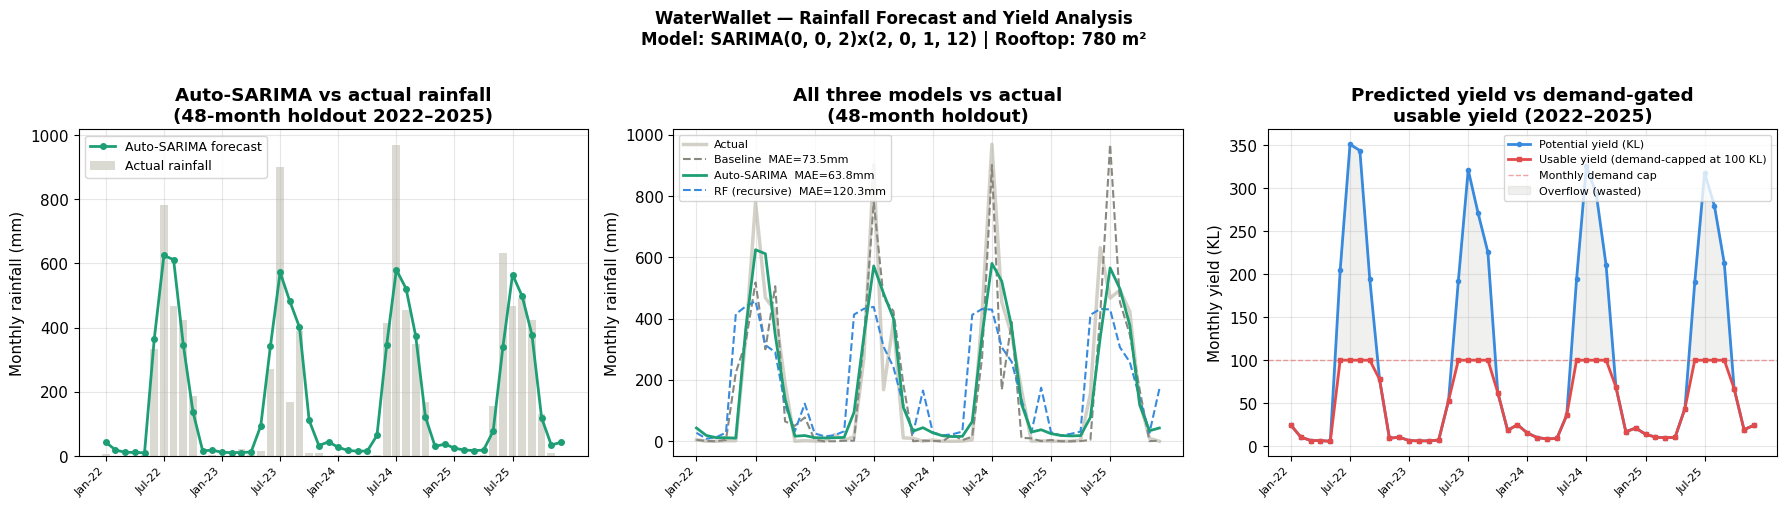

Saved: rainfall_forecast.png


In [ ]:
# ============================================================
# MISSING CHART 1 — rainfall_forecast.png
# Paste this AFTER Cell 8 (rainfall model comparison)
# Requires: sarima_fit, selected_rainfall, test_data,
#           actual_rainfall, calculate_yield_kl,
#           MONTHLY_DEMAND_KL, best_sarima_order
# ============================================================

"""
Generates rainfall_forecast.png
Three-panel chart:
  Left  : Auto-SARIMA predicted vs actual rainfall (2022–2025 test period)
  Centre: All three model predictions vs actual (comparison)
  Right : Predicted yield vs demand-gated usable yield (from selected model)
"""

month_labels = ['Jan','Feb','Mar','Apr','May','Jun',
                'Jul','Aug','Sep','Oct','Nov','Dec']

# Build a readable x-axis label: "Jan-22", "Feb-22" ... for 48 months
x_labels = []
for _, row in test_data.iterrows():
    x_labels.append(f"{month_labels[int(row['month'])-1]}-{str(int(row['year']))[2:]}")
x = np.arange(len(test_data))

# Yield arrays from selected model
predicted_yield    = calculate_yield_kl(np.array(selected_rainfall))
usable_pred_yield  = np.minimum(predicted_yield, MONTHLY_DEMAND_KL)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ── Panel A: Auto-SARIMA predicted vs actual ─────────────────────────────────
axes[0].bar(x, actual_rainfall, color='#D3D1C7', alpha=0.8,
            label='Actual rainfall', zorder=1)
axes[0].plot(x, sarima_predictions, 'o-', color='#1D9E75', linewidth=2,
             markersize=4, label=f'Auto-SARIMA forecast', zorder=2)
axes[0].set_xticks(x[::6])
axes[0].set_xticklabels(x_labels[::6], rotation=45, ha='right', fontsize=8)
axes[0].set_title(f'Auto-SARIMA vs actual rainfall\n(48-month holdout 2022–2025)',
                  fontweight='bold')
axes[0].set_ylabel('Monthly rainfall (mm)')
axes[0].legend(fontsize=9)

# ── Panel B: All three models vs actual ──────────────────────────────────────
axes[1].plot(x, actual_rainfall,    color='#D3D1C7', linewidth=2.5,
             label='Actual', zorder=1)
axes[1].plot(x, baseline_predictions, '--', color='#888780', linewidth=1.5,
             label=f'Baseline  MAE={mean_absolute_error(actual_rainfall, baseline_predictions):.1f}mm',
             zorder=2)
axes[1].plot(x, sarima_predictions,  '-',  color='#1D9E75', linewidth=2,
             label=f'Auto-SARIMA  MAE={mean_absolute_error(actual_rainfall, sarima_predictions):.1f}mm',
             zorder=3)
axes[1].plot(x, rf_predictions,      '--', color='#378ADD', linewidth=1.5,
             label=f'RF (recursive)  MAE={mean_absolute_error(actual_rainfall, rf_predictions):.1f}mm',
             zorder=2)
axes[1].set_xticks(x[::6])
axes[1].set_xticklabels(x_labels[::6], rotation=45, ha='right', fontsize=8)
axes[1].set_title('All three models vs actual\n(48-month holdout)', fontweight='bold')
axes[1].set_ylabel('Monthly rainfall (mm)')
axes[1].legend(fontsize=8)

# ── Panel C: Predicted yield vs usable yield ──────────────────────────────────
axes[2].plot(x, predicted_yield,   'o-', color='#378ADD', linewidth=2,
             markersize=3, label='Potential yield (KL)')
axes[2].plot(x, usable_pred_yield, 's-', color='#E24B4A', linewidth=2,
             markersize=3, label=f'Usable yield (demand-capped at {MONTHLY_DEMAND_KL} KL)')
axes[2].axhline(MONTHLY_DEMAND_KL, color='#E24B4A', linestyle='--',
                linewidth=1, alpha=0.5, label='Monthly demand cap')
axes[2].fill_between(x, usable_pred_yield, predicted_yield,
                     alpha=0.12, color='#888780', label='Overflow (wasted)')
axes[2].set_xticks(x[::6])
axes[2].set_xticklabels(x_labels[::6], rotation=45, ha='right', fontsize=8)
axes[2].set_title('Predicted yield vs demand-gated\nusable yield (2022–2025)',
                  fontweight='bold')
axes[2].set_ylabel('Monthly yield (KL)')
axes[2].legend(fontsize=8)

plt.suptitle(f'WaterWallet — Rainfall Forecast and Yield Analysis\n'
             f'Model: {best_sarima_order} | Rooftop: {ROOFTOP_AREA_M2} m²',
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('rainfall_forecast.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: rainfall_forecast.png')

In [ ]:
# ============================================================
# CELL 9 — Historical rainfall scenarios and ROI engine
# ============================================================
"""
Three historical years representing P10 (dry), P50 (typical), and
P90 (wet) annual rainfall percentiles are selected as scenario proxies.
The ROI engine runs a 10-year compounding simulation for each.

Key formula:
  Annual savings(year t) = usable_yield × tanker_rate × (1 + inflation)^(t-1)
  Net position(year t)   = cumulative savings − CAPEX − cumulative maintenance
  Break-even             = first year where Net position ≥ 0
"""

# Select scenario years
annual_rainfall = (
    rainfall.groupby('year', as_index=False)['rain_mm']
    .sum()
    .rename(columns={'rain_mm': 'annual_rain_mm'})
)

scenario_records = []
for pct in [0.10, 0.50, 0.90]:
    target_val   = annual_rainfall['annual_rain_mm'].quantile(pct)
    closest_year = annual_rainfall.iloc[
        (annual_rainfall['annual_rain_mm'] - target_val).abs().argmin()
    ]
    scenario_records.append({
        'scenario':       f'P{int(pct * 100)}',
        'source_year':    int(closest_year['year']),
        'annual_rain_mm': float(closest_year['annual_rain_mm'])
    })

scenario_summary = pd.DataFrame(scenario_records)
print('Historical rainfall scenarios:')
display(scenario_summary)

# Build monthly yield for each scenario
scenario_yield_rows = []
for _, sc in scenario_summary.iterrows():
    y_data = rainfall[rainfall['year'] == sc['source_year']].copy()
    y_data['scenario']         = sc['scenario']
    y_data['yield_kl']         = calculate_yield_kl(y_data['rain_mm'])
    y_data['usable_yield_kl']  = np.minimum(y_data['yield_kl'], MONTHLY_DEMAND_KL)
    scenario_yield_rows.append(y_data)

scenario_yield = pd.concat(scenario_yield_rows, ignore_index=True)

# ROI constants
TANKER_COST_PER_KL = 175  # Midpoint of the local ₹150–200/KL range
# Re-run the ROI cells to refresh saved outputs after changing this assumption.
CAPEX_INR          = 500_000
ANNUAL_OPEX_INR    = CAPEX_INR * 0.03   # 3% AMC — was incorrectly 0 before
INFLATION_RATE     = 0.08
ROI_YEARS          = 10

def calculate_roi(monthly_yield_data, scenario_name):
    first_year_savings = monthly_yield_data['usable_yield_kl'].sum() * TANKER_COST_PER_KL
    cumulative, payback_year, rows = -CAPEX_INR, None, []
    for year in range(1, ROI_YEARS + 1):
        net = (first_year_savings * (1 + INFLATION_RATE) ** (year - 1)) - ANNUAL_OPEX_INR
        cumulative += net
        if payback_year is None and cumulative >= 0:
            payback_year = year
        rows.append({
            'scenario':                scenario_name,
            'year':                    year,
            'annual_yield_kl':         monthly_yield_data['yield_kl'].sum(),
            'annual_usable_yield_kl':  monthly_yield_data['usable_yield_kl'].sum(),
            'first_year_savings_inr':  first_year_savings,
            'cumulative_cashflow_inr': cumulative,
            'payback_year':            payback_year
        })
    return pd.DataFrame(rows)

roi_table = pd.concat(
    [calculate_roi(scenario_yield[scenario_yield['scenario'] == s], s)
     for s in scenario_yield['scenario'].unique()],
    ignore_index=True
)

print('\nROI SUMMARY (Year 10):')
display(roi_table[roi_table['year'] == ROI_YEARS][[
    'scenario', 'annual_usable_yield_kl',
    'first_year_savings_inr', 'cumulative_cashflow_inr', 'payback_year'
]])

Historical rainfall scenarios:


,scenario,source_year,annual_rain_mm
0,P10,2015,1041.3
1,P50,2016,1730.6
2,P90,2019,2395.9



ROI SUMMARY (Year 10):


,scenario,annual_usable_yield_kl,first_year_savings_inr,cumulative_cashflow_inr,payback_year
9,P10,393.71680,314973.440,3.912882e+06,2.0
19,P50,462.11296,369690.368,4.705543e+06,2.0
29,P90,515.89328,412714.624,5.328816e+06,2.0


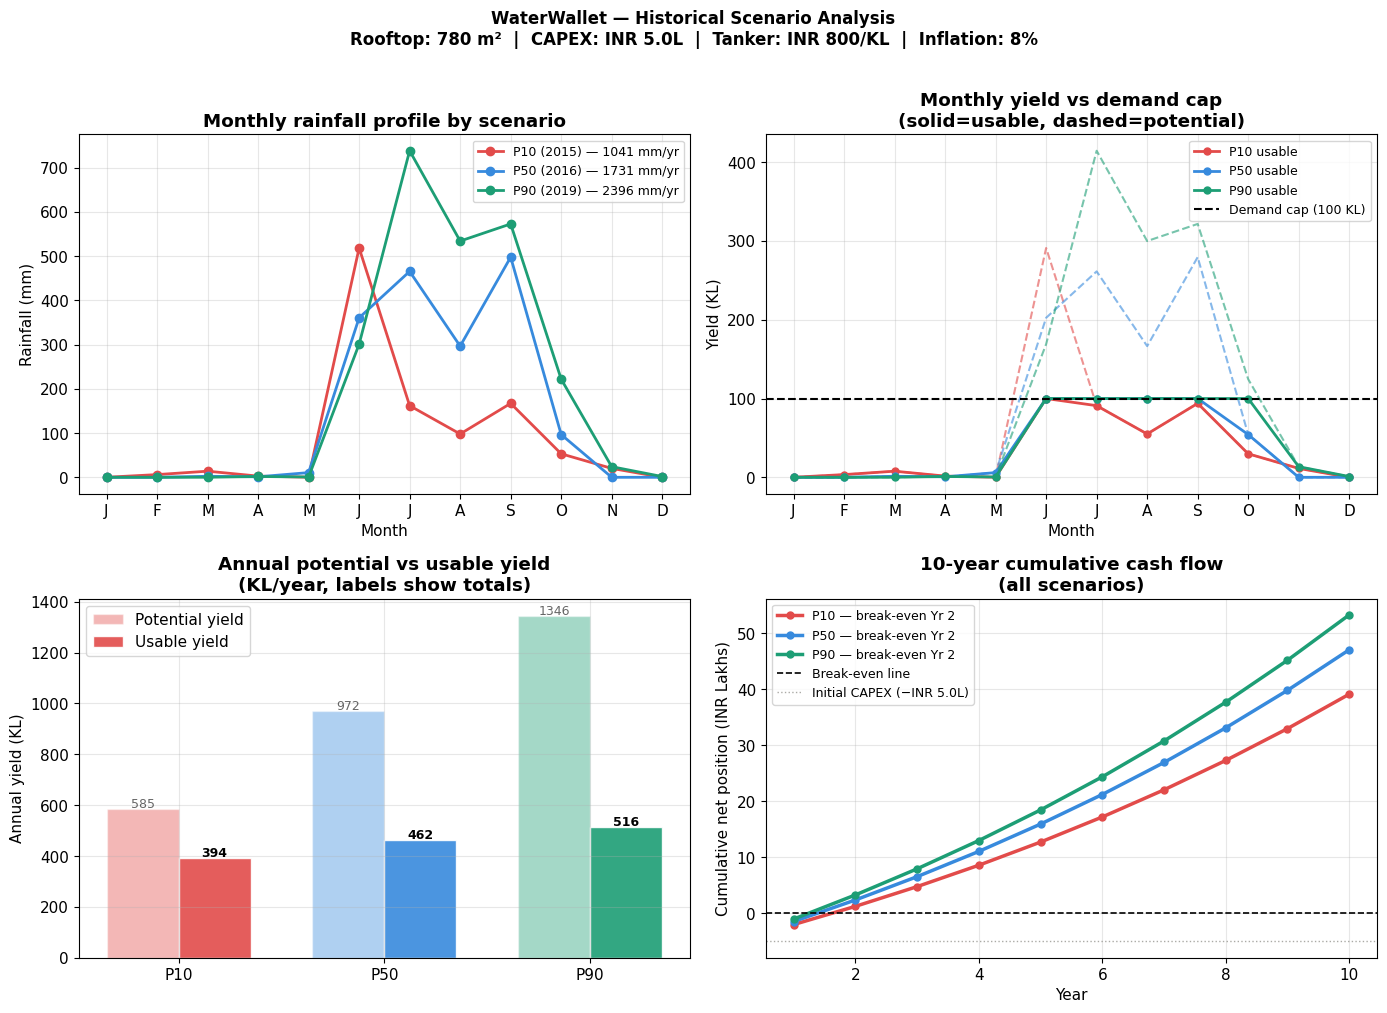

Saved: scenario_comparison.png


In [ ]:
# ============================================================
# MISSING CHART 2 — scenario_comparison.png
# Paste this AFTER Cell 9 (historical ROI engine)
# Requires: scenario_yield, scenario_summary, roi_table,
#           calculate_yield_kl, MONTHLY_DEMAND_KL,
#           CAPEX_INR, TANKER_COST_PER_KL
# ============================================================

"""
Generates scenario_comparison.png
Four-panel chart:
  Top-left  : Monthly rainfall profile for each scenario year
  Top-right : Monthly yield vs demand cap for each scenario
  Bot-left  : Annual totals — potential vs usable yield per scenario
  Bot-right : Cumulative 10-year cash flow per scenario with break-even
"""

SCENARIO_COLORS = {'P10': '#E24B4A', 'P50': '#378ADD', 'P90': '#1D9E75'}
month_names_short = ['J','F','M','A','M','J','J','A','S','O','N','D']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ── Panel A (top-left): Monthly rainfall profile ──────────────────────────────
for _, sc in scenario_summary.iterrows():
    label = sc['scenario']
    year  = int(sc['source_year'])
    rain  = scenario_yield[scenario_yield['scenario'] == label]['rain_mm'].values
    axes[0,0].plot(range(1,13), rain,
                   'o-', color=SCENARIO_COLORS[label], linewidth=2,
                   markersize=6,
                   label=f"{label} ({year}) — {sc['annual_rain_mm']:.0f} mm/yr")

axes[0,0].set_xticks(range(1,13))
axes[0,0].set_xticklabels(month_names_short)
axes[0,0].set_title('Monthly rainfall profile by scenario', fontweight='bold')
axes[0,0].set_xlabel('Month')
axes[0,0].set_ylabel('Rainfall (mm)')
axes[0,0].legend(fontsize=9)

# ── Panel B (top-right): Monthly yield vs demand cap ─────────────────────────
for _, sc in scenario_summary.iterrows():
    label     = sc['scenario']
    yld       = scenario_yield[scenario_yield['scenario'] == label]['yield_kl'].values
    usable    = scenario_yield[scenario_yield['scenario'] == label]['usable_yield_kl'].values
    axes[0,1].plot(range(1,13), yld,
                   '--', color=SCENARIO_COLORS[label], linewidth=1.5, alpha=0.6)
    axes[0,1].plot(range(1,13), usable,
                   'o-', color=SCENARIO_COLORS[label], linewidth=2,
                   markersize=5, label=f'{label} usable')

axes[0,1].axhline(MONTHLY_DEMAND_KL, color='black', linestyle='--',
                  linewidth=1.5, label=f'Demand cap ({MONTHLY_DEMAND_KL} KL)')
axes[0,1].set_xticks(range(1,13))
axes[0,1].set_xticklabels(month_names_short)
axes[0,1].set_title('Monthly yield vs demand cap\n(solid=usable, dashed=potential)',
                    fontweight='bold')
axes[0,1].set_xlabel('Month')
axes[0,1].set_ylabel('Yield (KL)')
axes[0,1].legend(fontsize=9)

# ── Panel C (bottom-left): Annual totals bar chart ───────────────────────────
scenarios_list = scenario_summary['scenario'].tolist()
pot_yields     = [scenario_yield[scenario_yield['scenario']==s]['yield_kl'].sum()
                  for s in scenarios_list]
usable_yields  = [scenario_yield[scenario_yield['scenario']==s]['usable_yield_kl'].sum()
                  for s in scenarios_list]

x_sc  = np.arange(len(scenarios_list))
width = 0.35
bars1 = axes[1,0].bar(x_sc - width/2, pot_yields, width,
                       color=[SCENARIO_COLORS[s] for s in scenarios_list],
                       alpha=0.4, edgecolor='white', label='Potential yield')
bars2 = axes[1,0].bar(x_sc + width/2, usable_yields, width,
                       color=[SCENARIO_COLORS[s] for s in scenarios_list],
                       alpha=0.9, edgecolor='white', label='Usable yield')

for bar, val in zip(bars1, pot_yields):
    axes[1,0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                   f'{val:.0f}', ha='center', fontsize=9, alpha=0.6)
for bar, val in zip(bars2, usable_yields):
    axes[1,0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                   f'{val:.0f}', ha='center', fontsize=9, fontweight='bold')

axes[1,0].set_xticks(x_sc)
axes[1,0].set_xticklabels(scenarios_list)
axes[1,0].set_title('Annual potential vs usable yield\n(KL/year, labels show totals)',
                    fontweight='bold')
axes[1,0].set_ylabel('Annual yield (KL)')
axes[1,0].legend()

# ── Panel D (bottom-right): 10-year cumulative cash flow ─────────────────────
for sc_name in scenarios_list:
    sc_roi = roi_table[roi_table['scenario'] == sc_name]
    axes[1,1].plot(sc_roi['year'], sc_roi['cumulative_cashflow_inr'] / 1e5,
                   'o-', color=SCENARIO_COLORS[sc_name], linewidth=2.5,
                   markersize=5,
                   label=f"{sc_name} — break-even Yr {sc_roi['payback_year'].dropna().min():.0f}"
                         if sc_roi['payback_year'].notna().any() else sc_name)

axes[1,1].axhline(0, color='black', linewidth=1.2, linestyle='--',
                  label='Break-even line')
axes[1,1].axhline(-CAPEX_INR / 1e5, color='#888780', linewidth=1,
                  linestyle=':', alpha=0.7, label=f'Initial CAPEX (−INR {CAPEX_INR/1e5:.1f}L)')
axes[1,1].set_title('10-year cumulative cash flow\n(all scenarios)',
                    fontweight='bold')
axes[1,1].set_xlabel('Year')
axes[1,1].set_ylabel('Cumulative net position (INR Lakhs)')
axes[1,1].legend(fontsize=9)

plt.suptitle(f'WaterWallet — Historical Scenario Analysis\n'
             f'Rooftop: {ROOFTOP_AREA_M2} m²  |  '
             f'CAPEX: INR {CAPEX_INR/1e5:.1f}L  |  '
             f'Tanker: INR {TANKER_COST_PER_KL}/KL  |  '
             f'Inflation: {int(INFLATION_RATE*100)}%',
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('scenario_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: scenario_comparison.png')

Running 1000 Monte Carlo ROI scenarios ...

MONTE CARLO ROI RESULTS
  Scenarios run           : 1000
  Median break-even       : Year 2
  Mean break-even         : Year 2.0
  Prob(break-even ≤ Yr 2) : 100.0%
  Prob(break-even ≤ Yr 3) : 100.0%
  Prob(break-even ≤ Yr 4) : 100.0%
  Prob(break-even ≤ Yr 5) : 100.0%
  Annual yield P10        : 460 KL
  Annual yield P50        : 505 KL
  Annual yield P90        : 546 KL


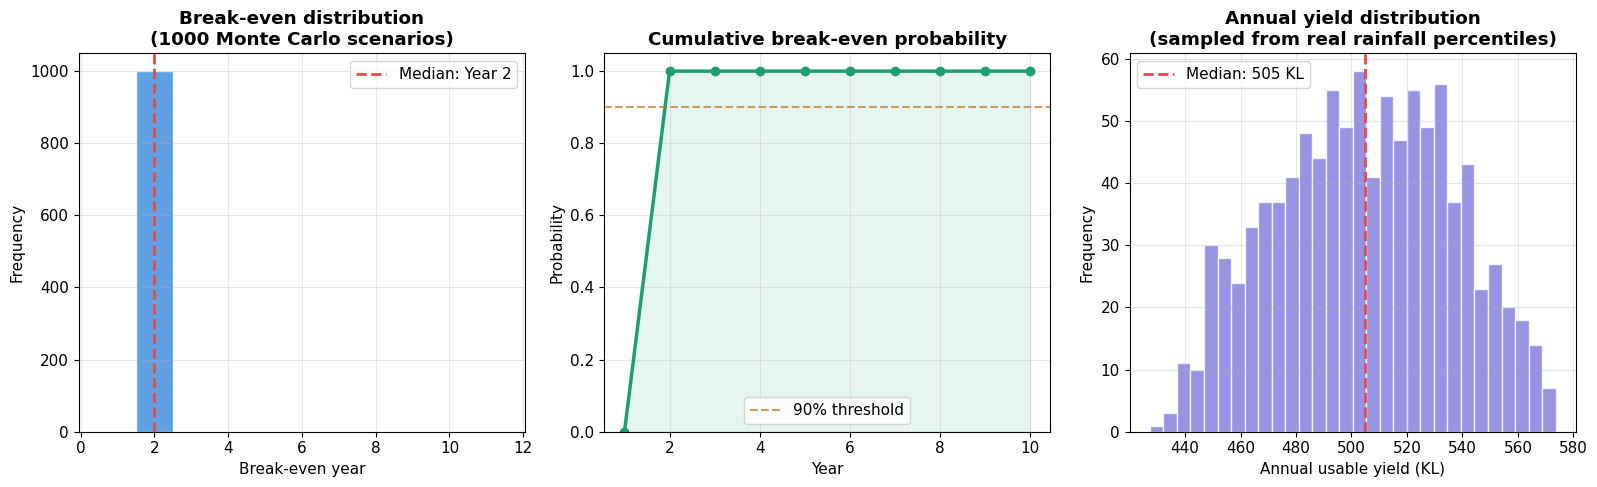

In [ ]:
# ============================================================
# CELL 10 — Monte Carlo ROI Simulation
# ============================================================
"""
Problem: The three scenario ROI uses three fixed rainfall years.
A single bad or good monsoon year does not capture the full range of
possible outcomes.

Fix: Sample 1,000 monthly rainfall values uniformly between P10 and P90
for each month, compute yield and run break-even. Output: a probability
distribution of break-even years rather than a single false-precision estimate.
"""

MC_SCENARIOS = 1000
np.random.seed(42)

# Monthly P10/P50/P90 from the full 2010–2025 dataset
rain_percentiles_mc = (
    monthly.groupby('month')['rain_mm']
    .quantile([0.10, 0.50, 0.90])
    .unstack(level=-1)
)
rain_percentiles_mc.columns = ['P10', 'P50', 'P90']

def sample_annual_yield(rain_pct_df, roof_area=ROOFTOP_AREA_M2,
                         usability=USABILITY_FACTOR,
                         runoff=RUNOFF_COEFFICIENT,
                         demand=MONTHLY_DEMAND_KL):
    """Sample one annual usable yield from the P10–P90 monthly distribution."""
    annual_usable = 0
    for m in range(1, 13):
        p10 = rain_pct_df.loc[m, 'P10']
        p90 = rain_pct_df.loc[m, 'P90']
        rain_sample  = np.random.uniform(p10, p90)
        monthly_yield = roof_area * max(0, rain_sample) * usability * runoff / 1000
        annual_usable += min(monthly_yield, demand)
    return annual_usable

def run_roi_single_scenario(annual_usable_kl):
    """Return break-even year for one yield scenario."""
    first_yr_savings = annual_usable_kl * TANKER_COST_PER_KL
    cumulative       = -CAPEX_INR
    for year in range(1, ROI_YEARS + 1):
        net        = (first_yr_savings * (1 + INFLATION_RATE) ** (year - 1)) - ANNUAL_OPEX_INR
        cumulative += net
        if cumulative >= 0:
            return year
    return ROI_YEARS + 1   # not achieved within horizon

print(f'Running {MC_SCENARIOS} Monte Carlo ROI scenarios ...')

breakeven_years = []
annual_yields   = []

for _ in range(MC_SCENARIOS):
    y_kl = sample_annual_yield(rain_percentiles_mc)
    breakeven_years.append(run_roi_single_scenario(y_kl))
    annual_yields.append(y_kl)

breakeven_arr = np.array(breakeven_years)
yields_arr    = np.array(annual_yields)

print('\nMONTE CARLO ROI RESULTS')
print(f'  Scenarios run           : {MC_SCENARIOS}')
print(f'  Median break-even       : Year {int(np.median(breakeven_arr))}')
print(f'  Mean break-even         : Year {np.mean(breakeven_arr):.1f}')
for yr in [2, 3, 4, 5]:
    print(f'  Prob(break-even ≤ Yr {yr}) : {(breakeven_arr <= yr).mean():.1%}')
print(f'  Annual yield P10        : {np.percentile(yields_arr, 10):.0f} KL')
print(f'  Annual yield P50        : {np.median(yields_arr):.0f} KL')
print(f'  Annual yield P90        : {np.percentile(yields_arr, 90):.0f} KL')

# Charts
scenario_colors_mc = {'P10': '#E24B4A', 'P50': '#378ADD', 'P90': '#1D9E75'}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# A: Break-even distribution
axes[0].hist(breakeven_arr, bins=range(1, ROI_YEARS + 3),
             color='#378ADD', alpha=0.8, edgecolor='white', align='left')
axes[0].axvline(np.median(breakeven_arr), color='#E24B4A', linewidth=2,
                linestyle='--', label=f'Median: Year {int(np.median(breakeven_arr))}')
axes[0].set_title(f'Break-even distribution\n({MC_SCENARIOS} Monte Carlo scenarios)',
                  fontweight='bold')
axes[0].set_xlabel('Break-even year')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# B: Cumulative probability
years      = np.arange(1, ROI_YEARS + 1)
cum_probs  = [(breakeven_arr <= y).mean() for y in years]
axes[1].plot(years, cum_probs, 'o-', color='#1D9E75', linewidth=2.5)
axes[1].fill_between(years, 0, cum_probs, alpha=0.1, color='#1D9E75')
axes[1].axhline(0.90, color='#BA7517', linestyle='--', alpha=0.7, label='90% threshold')
axes[1].set_title('Cumulative break-even probability', fontweight='bold')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Probability')
axes[1].set_ylim(0, 1.05)
axes[1].legend()

# C: Yield distribution
axes[2].hist(yields_arr, bins=30, color='#7F77DD', alpha=0.8, edgecolor='white')
axes[2].axvline(np.median(yields_arr), color='#E24B4A', linewidth=2,
                linestyle='--', label=f'Median: {np.median(yields_arr):.0f} KL')
axes[2].set_title('Annual yield distribution\n(sampled from real rainfall percentiles)',
                  fontweight='bold')
axes[2].set_xlabel('Annual usable yield (KL)')
axes[2].set_ylabel('Frequency')
axes[2].legend()

plt.tight_layout()
plt.savefig('monte_carlo_roi.png', dpi=150, bbox_inches='tight')
plt.show()

Generating 10,000 synthetic ROI scenarios ...
Gradient Boosting R² (5-fold CV): 0.979 ± 0.000

ROI SENSITIVITY — which input drives break-even most:
           Feature  Mean |SHAP|
         capex_inr     1.494829
  annual_demand_kl     1.278358
tanker_rate_inr_kl     0.622534
  tanker_inflation     0.221532
          amc_rate     0.142225
    annual_rain_mm     0.005070
      roof_area_m2     0.003597

Top driver : capex_inr


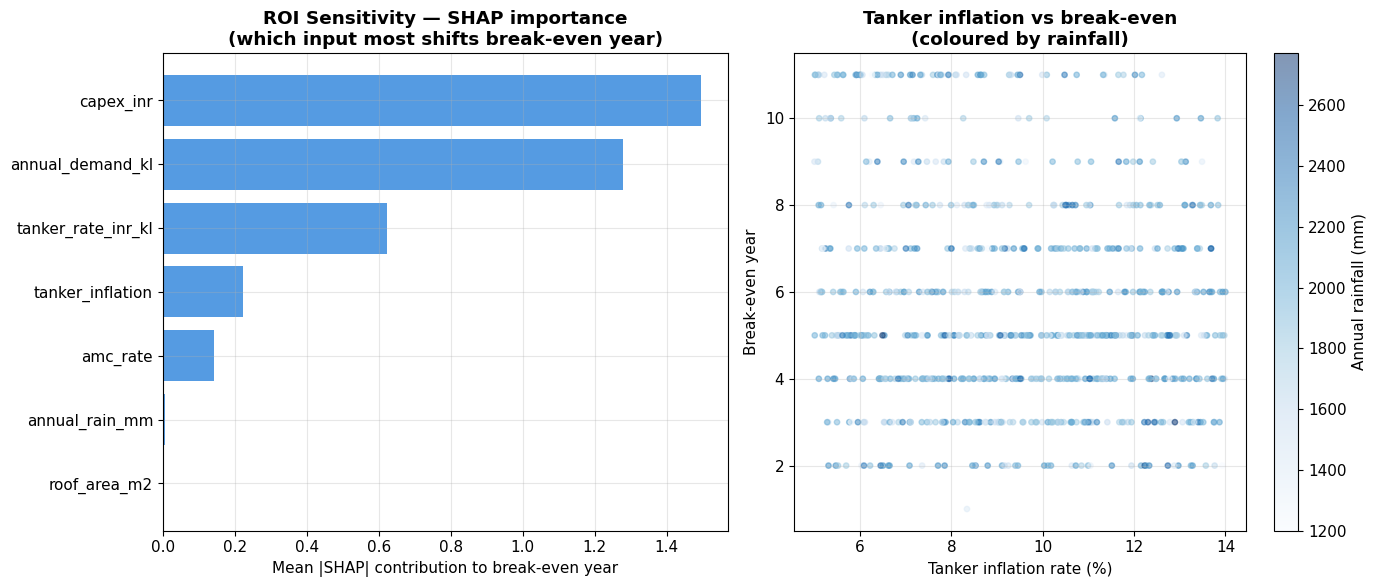

In [ ]:
# ============================================================
# CELL 11 — ROI Sensitivity Analysis (Gradient Boosting + SHAP)
# ============================================================
"""
Which input variable most drives the break-even year?
Generate 10,000 synthetic ROI scenarios by sampling all financial and
hydrological inputs from realistic ranges. Train GradientBoostingRegressor
to predict break-even year. Apply SHAP to rank variable sensitivity.
"""

SA_N = 10_000
np.random.seed(42)

sa_roof_area    = np.random.randint(300, 2000, SA_N)
sa_rainfall     = np.random.normal(1873, 280, SA_N).clip(1200, 3000)
sa_capex        = np.random.randint(200_000, 900_000, SA_N)
sa_inflation    = np.random.uniform(0.05, 0.14, SA_N)
sa_amc          = np.random.uniform(0.02, 0.05, SA_N)
sa_tanker_rate  = np.random.randint(600, 1100, SA_N)
sa_demand       = np.random.randint(60, 200, SA_N)

SA_FEATURES = [
    'roof_area_m2', 'annual_rain_mm', 'capex_inr',
    'tanker_inflation', 'amc_rate', 'tanker_rate_inr_kl', 'annual_demand_kl'
]

print(f'Generating {SA_N:,} synthetic ROI scenarios ...')

sa_breakeven = []
for i in range(SA_N):
    annual_yield = (sa_roof_area[i] * USABILITY_FACTOR *
                    (sa_rainfall[i] / 1000) * RUNOFF_COEFFICIENT)
    usable       = min(annual_yield, float(sa_demand[i]))
    first_sav    = usable * sa_tanker_rate[i]
    cumul        = -float(sa_capex[i])
    maint        = float(sa_capex[i]) * sa_amc[i]
    payback      = ROI_YEARS + 1
    for year in range(1, ROI_YEARS + 1):
        cumul += (first_sav * (1 + sa_inflation[i]) ** (year - 1)) - maint
        if cumul >= 0:
            payback = year
            break
    sa_breakeven.append(payback)

sa_X = pd.DataFrame({
    'roof_area_m2':       sa_roof_area,
    'annual_rain_mm':     sa_rainfall,
    'capex_inr':          sa_capex,
    'tanker_inflation':   sa_inflation,
    'amc_rate':           sa_amc,
    'tanker_rate_inr_kl': sa_tanker_rate,
    'annual_demand_kl':   sa_demand
})
sa_y = np.array(sa_breakeven)

gb_reg = GradientBoostingRegressor(
    n_estimators=300, max_depth=4,
    learning_rate=0.05, subsample=0.8, random_state=42
)
gb_reg.fit(sa_X, sa_y)

gb_cv = cross_val_score(gb_reg, sa_X, sa_y, cv=5, scoring='r2')
print(f'Gradient Boosting R² (5-fold CV): {gb_cv.mean():.3f} ± {gb_cv.std():.3f}')

sa_explainer   = shap.TreeExplainer(gb_reg)
shap_sample    = sa_X.sample(1000, random_state=42)
sa_shap_values = sa_explainer.shap_values(shap_sample)

sa_shap_df = pd.DataFrame({
    'Feature':      SA_FEATURES,
    'Mean |SHAP|':  np.abs(sa_shap_values).mean(axis=0)
}).sort_values('Mean |SHAP|', ascending=False)

print('\nROI SENSITIVITY — which input drives break-even most:')
print(sa_shap_df.to_string(index=False))
print(f"\nTop driver : {sa_shap_df.iloc[0]['Feature']}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sa_plot = sa_shap_df.sort_values('Mean |SHAP|', ascending=True)
axes[0].barh(sa_plot['Feature'], sa_plot['Mean |SHAP|'],
             color='#378ADD', alpha=0.85)
axes[0].set_title('ROI Sensitivity — SHAP importance\n'
                  '(which input most shifts break-even year)', fontweight='bold')
axes[0].set_xlabel('Mean |SHAP| contribution to break-even year')

scatter_idx = np.random.choice(len(sa_X), 800, replace=False)
sc = axes[1].scatter(
    sa_X.iloc[scatter_idx]['tanker_inflation'] * 100,
    sa_y[scatter_idx],
    c=sa_X.iloc[scatter_idx]['annual_rain_mm'],
    cmap='Blues', alpha=0.5, s=15
)
plt.colorbar(sc, ax=axes[1], label='Annual rainfall (mm)')
axes[1].set_xlabel('Tanker inflation rate (%)')
axes[1].set_ylabel('Break-even year')
axes[1].set_title('Tanker inflation vs break-even\n(coloured by rainfall)',
                  fontweight='bold')

plt.tight_layout()
plt.savefig('roi_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ============================================================
# CELL 12 — Tier 1 Safety Gate
# ============================================================
"""
Hard hydrogeological checks run BEFORE the ML classifier.
No model confidence can override a physical safety constraint.
Three checks:
  1. Coastal (≤ 2.5 km) → seawater intrusion risk → Storage-Only
  2. Impermeable soil (perm=1) + no borewell → recharge impossible
  3. Shallow borewell (< 30m) → too shallow for safe injection
"""

def tier1_safety_gate(site: dict):
    """
    Returns a forced result dict if any safety condition triggers.
    Returns None if site passes all checks (proceed to ML classifier).
    """
    if site.get('coastal_km', 99) <= 2.5:
        return {
            'config': 'Storage-Only', 'source': 'tier1_safety_gate',
            'safety_triggered': True,
            'reason': (
                f"Site is {site.get('coastal_km')} km from coastline. "
                "Recharge blocked — seawater intrusion risk "
                "(CGWB guideline: min 2.5 km)."
            )
        }
    if site.get('soil_perm', 3) == 1 and site.get('borewell', 0) == 0:
        return {
            'config': 'Storage-Only', 'source': 'tier1_safety_gate',
            'safety_triggered': True,
            'reason': (
                "Very low soil permeability (perm class 1) and no borewell. "
                "Surface recharge is physically infeasible."
            )
        }
    if site.get('borewell', 0) == 1 and site.get('borewell_depth', 99) < 30:
        return {
            'config': 'Storage-Only', 'source': 'tier1_safety_gate',
            'safety_triggered': True,
            'reason': (
                f"Borewell depth {site.get('borewell_depth')} m < 30 m. "
                "Too shallow for safe artificial recharge injection."
            )
        }
    return None   # all checks passed — proceed to ML

# Sanity tests
test_coastal  = {'coastal_km': 1.2, 'soil_perm': 3, 'borewell': 1, 'borewell_depth': 90}
test_good     = {'coastal_km': 18,  'soil_perm': 3, 'borewell': 1, 'borewell_depth': 95}
test_shallow  = {'coastal_km': 15,  'soil_perm': 3, 'borewell': 1, 'borewell_depth': 20}

print('Tier 1 safety gate tests:')
print(f'  Coastal (1.2 km) → {tier1_safety_gate(test_coastal)["config"]}')
print(f'  Good site        → {tier1_safety_gate(test_good)} (None = pass)')
print(f'  Shallow borewell → {tier1_safety_gate(test_shallow)["config"]}')

Tier 1 safety gate tests:
  Coastal (1.2 km) → Storage-Only
  Good site        → None (None = pass)
  Shallow borewell → Storage-Only


In [ ]:
# ============================================================
# CELL 13 ? Generate the production-aligned synthetic site dataset
# ============================================================
"""
600 synthetic site samples generated with the same feature distributions and
engineering label function as backend/ml_models/train_models.py. Statistics
use the backend training window (2010-2024), not the separate 2022-2025
rainfall-forecast evaluation window.
"""

classifier_monthly = monthly.loc[monthly['year'] <= 2024].copy()


def classify_rwh(row):
    """Match the production classifier's deterministic engineering labels."""
    coastal    = row['coastal_km'] <= 2.5
    has_bw     = row['borewell'] == 1
    deep_bw    = row['borewell_depth'] >= 30.0
    good_soil  = row['soil_perm'] >= 2
    large_roof = row['rooftop_area'] >= 500.0

    if coastal or not has_bw or not deep_bw or not good_soil:
        return 'Storage-Only'
    if large_roof:
        return 'Hybrid'
    return 'Borewell-Recharge'


np.random.seed(42)
N = 600

real_ann_mean  = classifier_monthly.groupby('year')['rain_mm'].sum().mean()
real_ann_std   = classifier_monthly.groupby('year')['rain_mm'].sum().std()
real_peak_mean = classifier_monthly['peak_day'].mean()

borewell       = np.random.choice([0, 1], N, p=[0.40, 0.60])
borewell_depth = np.where(borewell, np.random.randint(30, 200, N), 0).astype(float)

site_df = pd.DataFrame({
    'rooftop_area':   np.random.randint(150, 1800, N).astype(float),
    'borewell':       borewell.astype(float),
    'borewell_depth': borewell_depth,
    'soil_perm':      np.random.choice(
        [1, 2, 3, 4, 5], N, p=[0.08, 0.22, 0.40, 0.22, 0.08]
    ).astype(float),
    'coastal_km':     np.random.randint(1, 35, N).astype(float),
    'annual_rain_mm': np.random.normal(real_ann_mean, real_ann_std, N)
                          .clip(1200, 3500).round(0),
    'peak_day_mm':    np.random.normal(real_peak_mean, 18, N)
                          .clip(15, 180).round(1),
})
site_df['config'] = site_df.apply(classify_rwh, axis=1)

print('Production-aligned synthetic dataset class distribution:')
print(site_df['config'].value_counts())
print(f'\nTotal: {len(site_df)} samples (source: rule-derived, BMC/CPHEEO)')


In [ ]:
# ============================================================
# CELL 14 — Add the one real case study
# ============================================================
"""
Real Thane society — 24-month billing dataset + domain expert assessment.
Rooftop area: 710 m², borewell: 95m depth, laterite soil, 25 km from coast.
Expert ground truth: Hybrid.
Held out entirely from training and test splits.
"""

real_case = {
    'rooftop_area':   710,      # sq m — consistent with paper
    'borewell':       1,
    'borewell_depth': 95,       # metres
    'soil_perm':      3,        # Laterite, NBSS&LUP Ghodbunder Road
    'coastal_km':     25,
    'annual_rain_mm': int(real_ann_mean),
    'peak_day_mm':    float(real_peak_mean),
    'source':         'real_case_study',
    'config':         'Hybrid'  # domain expert ground truth
}

rule_pred = classify_rwh(real_case)
print(f'Real case — Expert ground truth : {real_case["config"]}')
print(f'Real case — Rule prediction     : {rule_pred}')
print(f'Match: {"Yes" if rule_pred == real_case["config"] else "No"}')
print('\nNote: rooftop_area is 710 m² (consistent with SHAP table in paper).')

In [ ]:
# ============================================================
# CELL 15 — EDA: visualise site classification dataset
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

counts = site_df['config'].value_counts()
bars = axes[0].bar(counts.index, counts.values,
                   color=[CONFIG_COLORS[c] for c in counts.index],
                   alpha=0.85, edgecolor='white')
for bar, val in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 3, str(val), ha='center', fontweight='bold')
axes[0].set_title('Class distribution\n(600 rule-derived samples)', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=10)

for config, grp in site_df.groupby('config'):
    axes[1].scatter(
        grp['soil_perm'] + np.random.uniform(-0.1, 0.1, len(grp)),
        grp['borewell_depth'] + np.random.uniform(-2, 2, len(grp)),
        alpha=0.45, s=25, label=config, color=CONFIG_COLORS[config]
    )
axes[1].set_xlabel('Soil permeability (1=low, 5=high)')
axes[1].set_ylabel('Borewell depth (m)')
axes[1].set_title('Soil type vs borewell depth by class', fontweight='bold')
axes[1].legend(fontsize=9)

config_order = list(CONFIG_COLORS.keys())
data_box = [site_df.loc[site_df['config'] == c, 'coastal_km'].values
            for c in config_order]
bp = axes[2].boxplot(data_box, patch_artist=True, labels=config_order)
for patch, cfg in zip(bp['boxes'], config_order):
    patch.set_facecolor(CONFIG_COLORS[cfg])
    patch.set_alpha(0.65)
axes[2].set_title('Coastal distance by class', fontweight='bold')
axes[2].set_ylabel('Distance from coast (km)')
axes[2].tick_params(axis='x', rotation=10)

plt.tight_layout()
plt.savefig('p2_eda.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ============================================================
# CELL 16 — Classifier train/test split
# ============================================================

CLF_FEATURES = [
    'rooftop_area', 'borewell', 'borewell_depth',
    'soil_perm', 'coastal_km', 'annual_rain_mm', 'peak_day_mm'
]

X_clf = site_df[CLF_FEATURES].values
y_clf = site_df['config'].values

le    = LabelEncoder()
y_enc = le.fit_transform(y_clf)

X_c_train, X_c_test, y_c_train, y_c_test = train_test_split(
    X_clf, y_enc, test_size=0.2, random_state=42, stratify=y_enc
)

print(f'Training set : {len(X_c_train)} samples')
print(f'Test set     : {len(X_c_test)} samples')
print(f'Classes      : {list(le.classes_)}')

In [ ]:
# ============================================================
# CELL 17 — Decision Tree classifier (baseline)
# ============================================================

dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_c_train, y_c_train)
dt_pred = dt.predict(X_c_test)
dt_acc  = accuracy_score(y_c_test, dt_pred)
cv_dt   = cross_val_score(dt, X_clf, y_enc, cv=5, scoring='accuracy')

print('DECISION TREE (baseline)')
print(f'  Test accuracy : {dt_acc:.3f}')
print(f'  5-fold CV     : {cv_dt.mean():.3f} ± {cv_dt.std():.3f}')
print()
print(classification_report(y_c_test, dt_pred, target_names=le.classes_))
print('Decision tree rules (top 4 levels):')
print(export_text(dt, feature_names=CLF_FEATURES, max_depth=4))

In [ ]:
# ============================================================
# CELL 18 ? Calibrated Random Forest classifier (production model)
# ============================================================

from sklearn.calibration import CalibratedClassifierCV

base_clf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_clf = CalibratedClassifierCV(base_clf, method='sigmoid', cv=5)
rf_clf.fit(X_c_train, y_c_train)
rf_clf_pred = rf_clf.predict(X_c_test)
rf_clf_acc = accuracy_score(y_c_test, rf_clf_pred)
cv_rf_clf = cross_val_score(rf_clf, X_clf, y_enc, cv=5, scoring='accuracy')

print('CALIBRATED RANDOM FOREST CLASSIFIER (production architecture)')
print(f'  Test accuracy : {rf_clf_acc:.3f}')
print(f'  5-fold CV     : {cv_rf_clf.mean():.3f} +/- {cv_rf_clf.std():.3f}')
print(f'  Improvement over DT: {(cv_rf_clf.mean()-cv_dt.mean())*100:+.1f}%')
print()
print(classification_report(y_c_test, rf_clf_pred, target_names=le.classes_))


In [ ]:
# ============================================================
# CELL 19 — Confusion matrix and model comparison chart
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, pred, title in zip(axes[:2],
                            [dt_pred, rf_clf_pred],
                            ['Decision Tree', 'Random Forest']):
    cm = confusion_matrix(y_c_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=le.classes_, yticklabels=le.classes_,
                linewidths=0.5, cbar=False)
    ax.set_title(f'{title} confusion matrix', fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.tick_params(axis='x', rotation=12)

bars = axes[2].bar(
    ['Decision\nTree', 'Random\nForest'],
    [cv_dt.mean(), cv_rf_clf.mean()],
    yerr=[cv_dt.std(), cv_rf_clf.std()],
    capsize=7, color=['#888780', '#1D9E75'], alpha=0.85, edgecolor='white'
)
axes[2].set_ylim(0.5, 1.05)
axes[2].set_title('5-fold CV accuracy comparison', fontweight='bold')
axes[2].set_ylabel('Cross-validation accuracy')
for bar, mean, std in zip(bars, [cv_dt.mean(), cv_rf_clf.mean()],
                               [cv_dt.std(), cv_rf_clf.std()]):
    axes[2].text(bar.get_x() + bar.get_width()/2, mean + std + 0.01,
                 f'{mean:.3f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('p2_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ============================================================
# CELL 20 ? Yield model comparison (production RF + research-only MLP)
# ============================================================
"""
The Random Forest data construction, features, target, estimator, and temporal
split mirror backend/ml_models/train_models.py. The separate MLP is retained
as a research comparison only; it is not used by the production API.
"""

ROOFTOP_SIZES = [200, 300, 400, 500, 600, 700, 800, 1000, 1200, 1500]
YIELD_FEATURES = [
    'rooftop_area', 'month', 'rain_mm', 'annual_rain_mm', 'peak_day_proxy',
    'lag1_rain', 'lag2_rain', 'lag3_rain', 'sin_month', 'cos_month'
]

# Production model training uses complete years through 2024. The separate
# rainfall forecast benchmark above retains its 2022-2025 holdout.
yield_monthly = monthly.loc[monthly['year'] <= 2024].copy()
yield_rows = []
for area in ROOFTOP_SIZES:
    m = yield_monthly.copy()
    m['lag1_rain'] = m['rain_mm'].shift(1).fillna(0)
    m['lag2_rain'] = m['rain_mm'].shift(2).fillna(0)
    m['lag3_rain'] = m['rain_mm'].shift(3).fillna(0)
    m['annual_rain_mm'] = m.groupby('year')['rain_mm'].transform('sum')
    m['sin_month'] = np.sin(2 * np.pi * m['month'] / 12)
    m['cos_month'] = np.cos(2 * np.pi * m['month'] / 12)
    m['rooftop_area'] = float(area)
    m['peak_day_proxy'] = m['rain_mm'] / 30.0
    m['yield_kl'] = calculate_yield_kl(m['rain_mm'], area)
    yield_rows.append(m)

yield_df = pd.concat(yield_rows, ignore_index=True)
train_mask = yield_df['year'] <= 2021
test_mask = yield_df['year'].between(2022, 2024)
X_yield_train = yield_df.loc[train_mask, YIELD_FEATURES]
y_yield_train = yield_df.loc[train_mask, 'yield_kl']
X_yield_test = yield_df.loc[test_mask, YIELD_FEATURES]
y_yield_test = yield_df.loc[test_mask, 'yield_kl']

print(f'Production-aligned yield rows: {len(yield_df)}')
print(f'Training samples: {len(X_yield_train)} (2010-2021)')
print(f'Test samples: {len(X_yield_test)} (2022-2024)')
print(f'Features: {YIELD_FEATURES}')

rf_yield = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_yield.fit(X_yield_train, y_yield_train)
rf_yield_pred = rf_yield.predict(X_yield_test).clip(0)
rf_yield_mae = mean_absolute_error(y_yield_test, rf_yield_pred)
rf_yield_r2 = r2_score(y_yield_test, rf_yield_pred)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_yield_train)
X_test_sc = scaler.transform(X_yield_test)

mlp = Sequential([
    Input(shape=(X_train_sc.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
], name='WaterWallet_MLP_ResearchOnly')
mlp.compile(optimizer='adam', loss='mse', metrics=['mae'])

early_stop = EarlyStopping(monitor='val_loss', patience=20,
                            restore_best_weights=True, verbose=0)
print('Training research-only MLP ...')
history_mlp = mlp.fit(
    X_train_sc, y_yield_train,
    epochs=200, batch_size=32,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=0
)
print(f'Stopped at epoch: {len(history_mlp.history["loss"])}')

mlp_pred = np.clip(mlp.predict(X_test_sc, verbose=0).flatten(), 0, None)
mlp_mae = mean_absolute_error(y_yield_test, mlp_pred)
mlp_r2 = r2_score(y_yield_test, mlp_pred)

print('\nYIELD PREDICTOR COMPARISON (KL/month)')
print(f'  Production RF MAE : {rf_yield_mae:.2f}   R2: {rf_yield_r2:.4f}')
print(f'  Research MLP MAE  : {mlp_mae:.2f}   R2: {mlp_r2:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history_mlp.history['loss'], label='Train loss', color='#378ADD')
axes[0].plot(history_mlp.history['val_loss'], label='Validation loss',
             color='#E24B4A', linestyle='--')
axes[0].set_title('Research-only MLP training loss', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE Loss')
axes[0].legend()

models_y = ['Production RF', 'Research MLP']
maes_y = [rf_yield_mae, mlp_mae]
r2s_y = [rf_yield_r2, mlp_r2]
bars = axes[1].bar(models_y, maes_y,
                   color=['#378ADD', '#7F77DD'], alpha=0.85, edgecolor='white')
for bar, mae, r2 in zip(bars, maes_y, r2s_y):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'MAE={mae:.1f}\nR2={r2:.3f}', ha='center', fontsize=9)
axes[1].set_title('Yield predictor comparison (lower MAE is better)', fontweight='bold')
axes[1].set_ylabel('Mean Absolute Error (KL/month)')
plt.tight_layout()
plt.savefig('dl_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


### Yield Predictor: Production-Aligned RF and Research MLP

The production-aligned yield dataset contains 1,800 rows (10 rooftop sizes × 180 months, 2010–2024), with 1,440 training rows (2010–2021) and 360 test rows (2022–2024). The Random Forest uses the production feature set and target. Its saved production metrics are MAE 4.8973 KL and R² 0.9865 (`backend/ml_models/model_metadata.json`).

The research-only MLP comparison uses the same aligned split, but its outputs were cleared after the feature and data-window correction. Rerun the notebook before reporting new MLP metrics; do not reuse earlier comparison values.

In [ ]:
# ============================================================
# CELL 21 — SHAP explainability (classifier)
# ============================================================

# Match backend/services/ml_engine.py by explaining the first calibrated forest.
shap_model = rf_clf
calibrated_models = getattr(rf_clf, 'calibrated_classifiers_', None)
if calibrated_models:
    shap_model = getattr(calibrated_models[0], 'estimator', calibrated_models[0])
explainer = shap.TreeExplainer(shap_model)
shap_values = explainer.shap_values(X_c_test)

# Handle both 3D (modern SHAP) and list (older SHAP) return types
if isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    # (n_samples, n_features, n_classes)
    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    class_importances = [mean_abs_shap[:, i] for i in range(mean_abs_shap.shape[1])]
else:
    class_importances = [np.abs(sv).mean(axis=0) for sv in shap_values]

global_importance = np.mean(class_importances, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

shap_df = pd.DataFrame({
    'Feature':      CLF_FEATURES,
    'Mean |SHAP|':  global_importance
}).sort_values('Mean |SHAP|', ascending=True)

axes[0].barh(shap_df['Feature'], shap_df['Mean |SHAP|'],
             color='#378ADD', alpha=0.8)
axes[0].set_title('Global SHAP feature importance', fontweight='bold')
axes[0].set_xlabel('Mean absolute SHAP value')

x_idx = np.arange(len(CLF_FEATURES))
width = 0.28
for i, (cls, color) in enumerate(CONFIG_COLORS.items()):
    cls_idx = list(le.classes_).index(cls)
    axes[1].bar(x_idx + i * width, class_importances[cls_idx],
                width=width, label=cls, color=color, alpha=0.8)
axes[1].set_xticks(x_idx + width)
axes[1].set_xticklabels(CLF_FEATURES, rotation=35, ha='right', fontsize=9)
axes[1].set_title('SHAP importance per class', fontweight='bold')
axes[1].set_ylabel('Mean absolute SHAP value')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('p2_shap.png', dpi=150, bbox_inches='tight')
plt.show()

print('Top 3 features:')
print(shap_df.sort_values('Mean |SHAP|', ascending=False).head(3).to_string(index=False))

In [ ]:
# ============================================================
# CELL 22 — Three Benchmarking Tests (ML vs Static Rules)
# ============================================================

import time

# ── TEST 1: Perturbation Noise Stability ─────────────────────────────────────
print('=' * 55)
print('BENCHMARKING TEST 1 — Perturbation Noise Stability')
print('=' * 55)

NOISE_LEVELS     = [0.05, 0.10, 0.20]
CONTINUOUS_FEATS = ['rooftop_area', 'borewell_depth',
                    'coastal_km', 'annual_rain_mm', 'peak_day_mm']

orig_ml_preds   = rf_clf.predict(site_df[CLF_FEATURES].values)
orig_rule_preds = site_df.apply(classify_rwh, axis=1).values

flip_results = []
np.random.seed(42)

for noise_level in NOISE_LEVELS:
    perturbed = site_df.copy()
    for col in CONTINUOUS_FEATS:
        noise = np.random.normal(0, noise_level * perturbed[col].std(), len(perturbed))
        perturbed[col] = (perturbed[col] + noise).clip(lower=0)

    perturbed_ml   = rf_clf.predict(perturbed[CLF_FEATURES].values)
    perturbed_rule = perturbed.apply(classify_rwh, axis=1).values

    flip_results.append({
        'Noise Level':    f'±{int(noise_level*100)}%',
        'ML Flip Rate':   round((orig_ml_preds   != perturbed_ml).mean(), 4),
        'Rule Flip Rate': round((orig_rule_preds != perturbed_rule).mean(), 4),
        'ML More Stable': (orig_ml_preds != perturbed_ml).mean() <
                          (orig_rule_preds != perturbed_rule).mean()
    })

flip_df = pd.DataFrame(flip_results)
print(flip_df.to_string(index=False))

# ── TEST 2: Boundary Continuity ───────────────────────────────────────────────
print('\n' + '=' * 55)
print('BENCHMARKING TEST 2 — Decision Boundary Continuity')
print('=' * 55)

coastal_range = np.linspace(0.5, 5.0, 100)
base_profile  = {
    'rooftop_area': 800, 'borewell': 1, 'borewell_depth': 100,
    'soil_perm': 3, 'annual_rain_mm': 1873, 'peak_day_mm': 65.0
}

ml_probs_list   = []
rule_preds_list = []

for d in coastal_range:
    site_test = {**base_profile, 'coastal_km': d}
    X_single  = np.array([[site_test[f] for f in CLF_FEATURES]])
    ml_probs_list.append(rf_clf.predict_proba(X_single)[0])
    rule_preds_list.append(classify_rwh(site_test))

ml_probs_arr = np.array(ml_probs_list)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, cls in enumerate(le.classes_):
    axes[0].plot(coastal_range, ml_probs_arr[:, i],
                 label=cls, linewidth=2, color=CONFIG_COLORS[cls])
axes[0].axvline(2.5, color='#E24B4A', linestyle='--', linewidth=1.5,
                label='Tier 1 threshold (2.5 km)')
axes[0].set_title('ML — smooth probability transition', fontweight='bold')
axes[0].set_xlabel('Distance from coastline (km)')
axes[0].set_ylabel('Predicted class probability')
axes[0].legend(fontsize=9)
axes[0].set_ylim(-0.05, 1.05)

config_map  = {'Storage-Only': 0, 'Borewell-Recharge': 1, 'Hybrid': 2}
rule_numeric = [config_map[r] for r in rule_preds_list]
axes[1].step(coastal_range, rule_numeric, color='#E24B4A', linewidth=2.5, where='post')
axes[1].set_title('Static rules — step-function cliff', fontweight='bold')
axes[1].set_xlabel('Distance from coastline (km)')
axes[1].set_yticks([0, 1, 2])
axes[1].set_yticklabels(le.classes_)
axes[1].axvline(3.0, color='#888780', linestyle='--', linewidth=1.5,
                label='Rule threshold (3.0 km)')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('boundary_continuity.png', dpi=150, bbox_inches='tight')
plt.show()

# ── TEST 3: Execution Latency ─────────────────────────────────────────────────
print('\n' + '=' * 55)
print('BENCHMARKING TEST 3 — Execution Latency')
print('=' * 55)

N_RUNS     = 200
BATCH_SIZE = 10_000
single_X   = site_df[CLF_FEATURES].iloc[[0]].values
single_row = site_df.iloc[0]

ml_times   = [(lambda: rf_clf.predict(single_X))() or time.perf_counter()]
ml_times   = []
for _ in range(N_RUNS):
    t0 = time.perf_counter()
    rf_clf.predict(single_X)
    ml_times.append((time.perf_counter() - t0) * 1000)

rule_times = []
for _ in range(N_RUNS):
    t0 = time.perf_counter()
    classify_rwh(single_row)
    rule_times.append((time.perf_counter() - t0) * 1000)

reps     = math.ceil(BATCH_SIZE / len(site_df))
batch_df = pd.concat([site_df] * reps, ignore_index=True).iloc[:BATCH_SIZE]

t0 = time.perf_counter()
rf_clf.predict(batch_df[CLF_FEATURES].values)
ml_batch_ms = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
batch_df.apply(classify_rwh, axis=1)
rule_batch_ms = (time.perf_counter() - t0) * 1000

latency_df = pd.DataFrame({
    'System':            ['Static Rules', 'ML (Random Forest)'],
    'Single Query (ms)': [round(np.mean(rule_times), 3), round(np.mean(ml_times), 3)],
    'Batch 10k (ms)':    [round(rule_batch_ms, 1), round(ml_batch_ms, 1)],
    'Under 15ms':        [np.mean(rule_times) < 15, np.mean(ml_times) < 15]
})
print(latency_df.to_string(index=False))

# Benchmarking summary chart
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot([f'±{int(n*100)}%' for n in NOISE_LEVELS],
             flip_df['ML Flip Rate'], 'o-', color='#378ADD',
             linewidth=2, label='ML Classifier')
axes[0].plot([f'±{int(n*100)}%' for n in NOISE_LEVELS],
             flip_df['Rule Flip Rate'], 's--', color='#E24B4A',
             linewidth=2, label='Static Rules')
axes[0].set_title('Test 1: Flip rate under noise\n(lower = more stable)', fontweight='bold')
axes[0].set_ylabel('Flip rate')
axes[0].set_xlabel('Noise level')
axes[0].legend()

axes[1].axis('off')
axes[1].text(0.5, 0.6, 'Test 2: Boundary Continuity',
             ha='center', va='center', fontsize=13, fontweight='bold',
             transform=axes[1].transAxes)
axes[1].text(0.5, 0.4,
             'ML → smooth sigmoid\nRules → step-function cliff\n'
             'See boundary_continuity.png',
             ha='center', va='center', fontsize=10, transform=axes[1].transAxes)

bars = axes[2].bar(['Static\nRules', 'ML\nClassifier'],
                   [np.mean(rule_times), np.mean(ml_times)],
                   color=['#888780', '#378ADD'], alpha=0.85, edgecolor='white')
axes[2].axhline(15, color='#E24B4A', linestyle='--', linewidth=1.5, label='15ms threshold')
for bar, lat in zip(bars, [np.mean(rule_times), np.mean(ml_times)]):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                 f'{lat:.3f} ms', ha='center', fontweight='bold')
axes[2].set_title('Test 3: Single-query latency', fontweight='bold')
axes[2].set_ylabel('Latency (ms)')
axes[2].legend()

plt.tight_layout()
plt.savefig('benchmarking_summary.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nAll benchmarking tests complete.')

In [ ]:
# ============================================================
# CELL 23 — Real case study validation
# ============================================================

real_X_df  = pd.DataFrame([[real_case[f] for f in CLF_FEATURES]],
                           columns=CLF_FEATURES)
pred_enc   = rf_clf.predict(real_X_df)[0]
pred_label = le.inverse_transform([pred_enc])[0]
pred_proba = rf_clf.predict_proba(real_X_df)[0]

print('═' * 52)
print('  REAL CASE STUDY VALIDATION — THANE SOCIETY')
print('═' * 52)
print(f'  Expert ground truth : {real_case["config"]}')
print(f'  Model prediction    : {pred_label}')
correct = pred_label == real_case['config']
print(f'  Result              : {"✓ CORRECT" if correct else "✗ MISMATCH"}')
print()
for cls, prob in sorted(zip(le.classes_, pred_proba), key=lambda x: x[1], reverse=True):
    bar = '█' * int(prob * 25)
    print(f'    {cls:<25} {bar:<25} {prob:.1%}')

# SHAP for this specific site
shap_single = explainer.shap_values(real_X_df.values)
if isinstance(shap_single, np.ndarray) and shap_single.ndim == 3:
    contrib = shap_single[0, :, pred_enc]
else:
    contrib = shap_single[pred_enc][0]

contrib_df = pd.DataFrame({'Feature': CLF_FEATURES, 'SHAP': contrib})\
               .sort_values('SHAP', key=abs, ascending=False)
print(f'\n  Why {pred_label}? (SHAP feature contributions)')
print(contrib_df.to_string(index=False))

In [ ]:
# ============================================================
# CELL 24 — Final evaluation summary and dashboard chart
# ============================================================

print('=' * 70)
print('WATERWALLET — FINAL EVALUATION SUMMARY')
print('=' * 70)

print('\n── RAINFALL MODELS ──────────────────────────────────────────')
print(f'  Data source     : Open-Meteo (Thane, 2010–2025, real data)')
print(f'  Selected model  : {best_model_name}')
print(f'  SARIMA order    : {best_sarima_order}')
display(metrics)

print('\n── YIELD PREDICTOR (Production RF vs research MLP) ────────')
print(f'  Random Forest MAE : {rf_yield_mae:.2f} KL   R²: {rf_yield_r2:.4f}')
print(f'  MLP Neural Net MAE: {mlp_mae:.2f} KL   R²: {mlp_r2:.4f}')
lower_mae_model = 'Random Forest' if rf_yield_mae <= mlp_mae else 'MLP'
print(f'  Lower-MAE model on this split: {lower_mae_model}.')

print('\n── HISTORICAL SCENARIOS ─────────────────────────────────────')
display(scenario_summary)

print('\n── ROI SUMMARY (Year 10) ───────────────────────────────────')
display(roi_table[roi_table['year'] == ROI_YEARS][[
    'scenario', 'annual_usable_yield_kl',
    'first_year_savings_inr', 'cumulative_cashflow_inr', 'payback_year'
]])

print('\n── MONTE CARLO ─────────────────────────────────────────────')
for yr in [2, 3, 4, 5]:
    print(f'  Prob(break-even ≤ Yr {yr}) : {(breakeven_arr <= yr).mean():.1%}')

print('\n── CLASSIFIER ──────────────────────────────────────────────')
print(f'  Decision Tree CV : {cv_dt.mean():.3f} ± {cv_dt.std():.3f}')
print(f'  Random Forest CV : {cv_rf_clf.mean():.3f} ± {cv_rf_clf.std():.3f}')
print(f'  Real case        : {pred_label} ({max(pred_proba):.1%} confidence) '
      f'→ {"✓ CORRECT" if correct else "✗ MISMATCH"}')

print('\n── DATA TRANSPARENCY ───────────────────────────────────────')
print('  Rainfall data           : Real — Open-Meteo Archive API (2010–2025)')
print('  Yield calculation       : Physics formula (IS:1172)')
print('  Rainfall models         : Same-Month Baseline, Auto-SARIMA, RF (recursive)')
print('  Classifier training     : Rule-derived synthetic (BMC/CPHEEO)')
print('  Classifier validation   : 1 real Thane society (held-out)')
print('=' * 70)

# ── Final dashboard chart ─────────────────────────────────────────────────────
scenario_colors_chart = {'P10': '#E24B4A', 'P50': '#378ADD', 'P90': '#1D9E75'}

fig = plt.figure(figsize=(18, 10), constrained_layout=True)
gs  = fig.add_gridspec(2, 3)

# A: 12-month rainfall + yield forecast
forecast_steps = 12
forecast_dates = pd.date_range(
    start=rainfall['date'].max() + pd.DateOffset(months=1),
    periods=forecast_steps, freq='MS'
)
sarima_fcast = np.maximum(sarima_fit.predict(n_periods=forecast_steps), 0)
fcast_df = pd.DataFrame({
    'date': forecast_dates,
    'predicted_rain_mm': sarima_fcast,
    'predicted_yield_kl': calculate_yield_kl(sarima_fcast)
})

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(fcast_df['date'], fcast_df['predicted_rain_mm'],
         'o-', linewidth=2, color='#378ADD', label='Predicted rainfall')
ax1.set_title(f'12-month forecast\n({best_sarima_order})', fontweight='bold')
ax1.set_ylabel('Rainfall (mm)', color='#378ADD')
ax1.tick_params(axis='x', rotation=45)
ax1_y = ax1.twinx()
ax1_y.plot(fcast_df['date'], fcast_df['predicted_yield_kl'],
           's--', linewidth=2, color='#1D9E75', label='Yield (KL)')
ax1_y.set_ylabel('Predicted yield (KL)', color='#1D9E75')
l1, lb1 = ax1.get_legend_handles_labels()
l2, lb2 = ax1_y.get_legend_handles_labels()
ax1.legend(l1 + l2, lb1 + lb2, fontsize=8)

# B: Scenario yield bars
ax2 = fig.add_subplot(gs[0, 1])
totals = scenario_yield.groupby('scenario')['yield_kl'].sum()
bars   = ax2.bar(totals.index, totals.values,
                 color=[scenario_colors_chart.get(s, '#888') for s in totals.index])
for bar, v in zip(bars, totals.values):
    ax2.text(bar.get_x() + bar.get_width()/2, v, f'{v:.0f} KL',
             ha='center', va='bottom')
ax2.set_title('Annual yield by scenario', fontweight='bold')
ax2.set_ylabel('Harvestable water (KL)')

# C: Classifier recommendation
ax3 = fig.add_subplot(gs[0, 2])
sorted_probs = sorted(zip(le.classes_, pred_proba), key=lambda x: x[1], reverse=True)
lbls  = [x[0] for x in sorted_probs]
probs = [x[1] for x in sorted_probs]
bars3 = ax3.barh(lbls[::-1], probs[::-1],
                 color=[CONFIG_COLORS.get(l, '#888') for l in lbls[::-1]])
for bar, p in zip(bars3, probs[::-1]):
    ax3.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height()/2,
             f'{p:.1%}', va='center')
ax3.set_xlim(0, 1.2)
ax3.set_title(f'RWH recommendation\n{pred_label}', fontweight='bold')

# D: Rainfall model MAE comparison
ax4 = fig.add_subplot(gs[1, 0])
model_colors_chart = {
    'Same-Month-Last-Year': '#888780',
    f'Auto-SARIMA ({best_sarima_order})': '#1D9E75',
    'Random Forest (recursive)': '#378ADD'
}
ax4.bar(metrics['Model'], metrics['MAE_mm'],
        color=[model_colors_chart.get(m, '#888') for m in metrics['Model']])
ax4.set_title('Rainfall model comparison\n(lower MAE = better)', fontweight='bold')
ax4.set_ylabel('MAE (mm)')
ax4.tick_params(axis='x', rotation=15)

# E: ROI cumulative cash flow
ax5 = fig.add_subplot(gs[1, 1])
for sn, grp in roi_table.groupby('scenario'):
    ax5.plot(grp['year'], grp['cumulative_cashflow_inr'],
             marker='o', label=sn, color=scenario_colors_chart.get(sn, '#888'))
ax5.axhline(0, color='black', linewidth=1, linestyle='--')
ax5.set_title('10-year cumulative cash flow', fontweight='bold')
ax5.set_xlabel('Year')
ax5.set_ylabel('Net position (INR)')
ax5.legend()

# F: SHAP explanation for real case
ax6 = fig.add_subplot(gs[1, 2])
shap_plot = contrib_df.sort_values('SHAP')
ax6.barh(shap_plot['Feature'], shap_plot['SHAP'],
         color=['#1D9E75' if v > 0 else '#E24B4A' for v in shap_plot['SHAP']])
ax6.axvline(0, color='black', linewidth=0.8)
ax6.set_title(f'SHAP: why {pred_label}?\n(Thane society)', fontweight='bold')
ax6.set_xlabel('SHAP contribution')

fig.suptitle('WaterWallet — Complete ML Results Dashboard',
             fontsize=16, fontweight='bold')
plt.savefig('waterwallet_final_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print('\nAll charts saved. Notebook complete.')